# OPPORTUNITY HAR: Comprehensive Preprocessing & Exploratory Data Analysis (EDA)

This notebook provides an end-to-end, reproducible guide for:
1. **Raw Sensor Stream Exploration**: Inspecting 24 UCI OPPORTUNITY recording files, parsing sensor channels and official modalities.
2. **Missing Value & Signal Quality Analysis**: Inspecting sensor dropout, packet loss, and linear interpolation for inertial channels.
3. **Exploratory Data Analysis (EDA)**:
   - Multimodal waveform visualization (Trunk accelerometer, IMUs, shoe sensors)
   - Sampling frequency and timestamp consistency checks (~30 Hz)
   - Locomotion activity class distribution and imbalance analysis
   - Anatomical body-region decomposition (Trunk, Right Arm, Left Arm, Right Leg, Left Leg)
4. **Leak-Free Preprocessing Pipeline**:
   - Zero data-leakage standard scaling (statistics fitted strictly on training subjects/runs)
   - Fixed-size sliding-window segmentation (30 timesteps = 1.0 s, 50% stride)
   - Continuous-run boundary preservation and window mode label assignment
5. **Windowed Tensor Verification & Feature Inspection**:
   - Verification of train/val/test tensor shapes: `(N, 133, 30)`
   - Window waveform inspection across distinct human physical actions.


## 0. Environment Setup & Repository Configuration

In [1]:
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import json

# Configure plot styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.size'] = 10

# Detect workspace root
current_dir = Path.cwd().resolve()
REPO_ROOT = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

# Ensure dataset path is discoverable
candidate_raw = REPO_ROOT / "data" / "raw" / "opportunity" / "OpportunityUCIDataset" / "dataset"
if candidate_raw.exists():
    os.environ["OPPORTUNITY_DATA_DIR"] = str(candidate_raw)

import src.api as api
setup_info = api.setup_project(seed=42)
print("Project Status:")
for k, v in setup_info.items():
    print(f"  {k:16s}: {v}")


[2026-10-26 11:17:33] [INFO] [api]: Project initialized. Device: cpu (CPU). Colab: False (Drive: False)


Project Status:
  repo_root       : C:\Users\DELL\OneDrive\Dokumen\har\Opportunity_HAR
  is_colab        : False
  drive_mounted   : False
  device          : cpu
  cuda_available  : False
  device_name     : CPU
  seed            : 42


## 1. Raw Dataset Audit & Sensor Channel Architecture

The UCI OPPORTUNITY dataset comprises continuous recordings from 4 subjects across 5 Activities of Daily Living (ADL) runs and 1 Drill run per subject (24 total recording files).
Each record captures 242 columns consisting of:
- **Timestamp** (column 0)
- **On-body sensors** (133 channels: custom accelerometers, inertial measurement units / IMUs on limbs and back, and shoe-mounted pressure/inertial sensors)
- **Ambient and object-mounted sensors**
- **Activity ground truth labels** (Locomotion, Gesture, High-Level tasks).


In [2]:
ds_status = api.locate_dataset()
print("Dataset Discovery Report:")
print("  Found           :", ds_status["found"])
print("  Files located   :", f"{ds_status['files_found']}/{ds_status['total_expected']}")
print("  Dataset Path    :", ds_status["dataset_dir"])

# Load generated metadata
meta_path = REPO_ROOT / "data" / "processed" / "sensor_metadata.json"
act_path = REPO_ROOT / "data" / "processed" / "activity_metadata.json"

if meta_path.exists():
    with open(meta_path, "r") as f:
        sensor_meta = json.load(f)
    print(f"\nSensor Metadata Summary:")
    print(f"  Total Channels in Raw File : {sensor_meta['total_columns']}")
    print(f"  Nominal Sampling Rate      : {sensor_meta['sampling_rate_nominal_hz']} Hz")
    print(f"  On-Body Sensor Channels    : {sensor_meta['on_body_sensor_channels_count']}")


Dataset Discovery Report:
  Found           : True
  Files located   : 24/24
  Dataset Path    : C:\Users\DELL\OneDrive\Dokumen\har\Opportunity_HAR\data\raw\opportunity\OpportunityUCIDataset\dataset

Sensor Metadata Summary:
  Total Channels in Raw File : 250
  Nominal Sampling Rate      : 30.0 Hz
  On-Body Sensor Channels    : 133


## 2. Inspecting a Continuous Raw Recording (Subject 1, ADL 1)

Let's load a continuous recording session (`S1-ADL1`) to examine the sampling regularity, missing rate, and signal distributions before any windowing or standardization.


In [3]:
# Load S1-ADL1 raw continuous stream
raw_data, raw_labels, raw_timestamps = api.load_opportunity_data(
    subject="S1",
    run="ADL1",
    target_track="Locomotion",
    sensor_selection="on_body",
    interpolate_nans=False  # Keep NaNs to analyze missingness
)

print(f"Continuous Recording Shape : {raw_data.shape} (timesteps, on-body channels)")
print(f"Total Samples (Timesteps)  : {len(raw_labels):,}")
print(f"Duration                   : {len(raw_labels) / 30.0 / 60.0:.2f} minutes")

# Check time intervals between consecutive samples (nominal ~33.3 ms for 30 Hz)
time_diffs = np.diff(raw_timestamps)
print(f"Timestamp Deltas (ms)      : Median={np.median(time_diffs):.1f} ms, Mean={np.mean(time_diffs):.1f} ms, Min={np.min(time_diffs):.1f} ms, Max={np.max(time_diffs):.1f} ms")


[2026-10-26 11:17:33] [INFO] [opportunity_loader]: OpportunityLoader initialized: 133 sensor channels, target track 'Locomotion' (col 243)


Continuous Recording Shape : (51116, 133) (timesteps, on-body channels)
Total Samples (Timesteps)  : 51,116
Duration                   : 28.40 minutes
Timestamp Deltas (ms)      : Median=33.0 ms, Mean=33.3 ms, Min=33.0 ms, Max=34.0 ms


## 3. Sensor Quality & Missing Value Imputation

Body sensor networks experience wireless packet loss and intermittent sensor dropouts.
Below, we evaluate the NaN distribution across the 133 on-body channels and demonstrate the linear interpolation strategy applied.


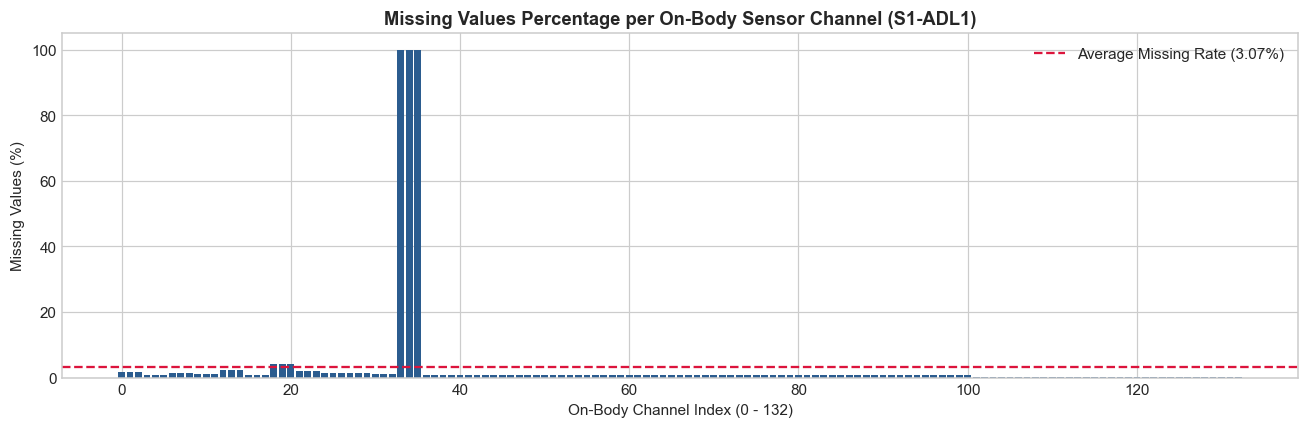

NaN count before interpolation: 208,808
NaN count after interpolation : 0


In [4]:
# Calculate percentage of missing values per on-body channel
nan_percentages = np.isnan(raw_data).mean(axis=0) * 100

fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(range(len(nan_percentages)), nan_percentages, color="#2b5c8f", width=0.8)
ax.axhline(np.mean(nan_percentages), color="crimson", linestyle="--", label=f"Average Missing Rate ({np.mean(nan_percentages):.2f}%)")
ax.set_title("Missing Values Percentage per On-Body Sensor Channel (S1-ADL1)", fontweight="bold")
ax.set_xlabel("On-Body Channel Index (0 - 132)")
ax.set_ylabel("Missing Values (%)")
ax.legend()
plt.tight_layout()
plt.show()

# Impute using linear interpolation (standard for continuous inertial HAR signals)
from src.data.opportunity_loader import OpportunityLoader
interpolated_data = OpportunityLoader.interpolate_missing(raw_data)
print(f"NaN count before interpolation: {np.isnan(raw_data).sum():,}")
print(f"NaN count after interpolation : {np.isnan(interpolated_data).sum():,}")


## 4. Multi-Sensor Time-Series Waveforms & Activity Alignment

In this section, we visualize aligned sensor streams from diverse body locations:
- **Trunk Accelerometer** (Torso dynamics)
- **Right Arm IMU** (Upper limb movement)
- **Shoe Sensor / Leg Acc** (Lower limb gait)
- Ground Truth **Locomotion Activity Labels**


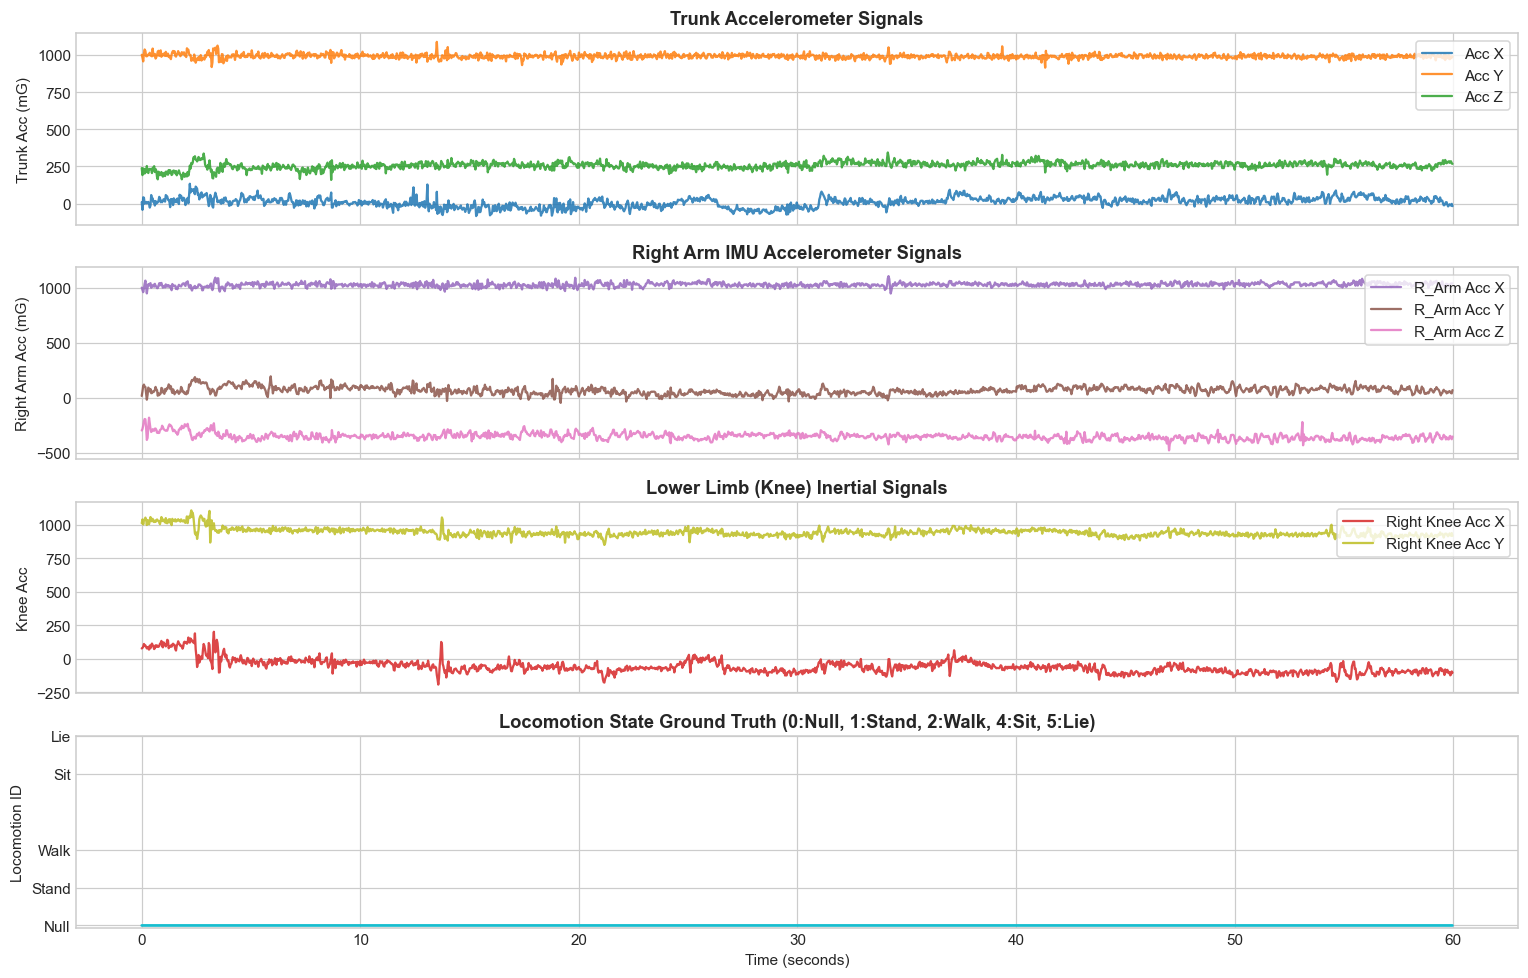

In [5]:
# Window of interest: 60 seconds (1800 timesteps)
start_idx = 1000
end_idx = 2800
t_range = slice(start_idx, end_idx)
time_axis = (raw_timestamps[t_range] - raw_timestamps[start_idx]) / 1000.0  # seconds

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)

# 1. Trunk Acceleration (Channels 3, 4, 5 corresponding to BACK Custom Acc)
axes[0].plot(time_axis, interpolated_data[t_range, 3], label="Acc X", color="#1f77b4", alpha=0.85)
axes[0].plot(time_axis, interpolated_data[t_range, 4], label="Acc Y", color="#ff7f0e", alpha=0.85)
axes[0].plot(time_axis, interpolated_data[t_range, 5], label="Acc Z", color="#2ca02c", alpha=0.85)
axes[0].set_ylabel("Trunk Acc (mG)")
axes[0].set_title("Trunk Accelerometer Signals", fontweight="bold")
axes[0].legend(loc="upper right", frameon=True)

# 2. Right Arm IMU Accelerometer
axes[1].plot(time_axis, interpolated_data[t_range, 25], label="R_Arm Acc X", color="#9467bd", alpha=0.85)
axes[1].plot(time_axis, interpolated_data[t_range, 26], label="R_Arm Acc Y", color="#8c564b", alpha=0.85)
axes[1].plot(time_axis, interpolated_data[t_range, 27], label="R_Arm Acc Z", color="#e377c2", alpha=0.85)
axes[1].set_ylabel("Right Arm Acc (mG)")
axes[1].set_title("Right Arm IMU Accelerometer Signals", fontweight="bold")
axes[1].legend(loc="upper right", frameon=True)

# 3. Leg / Shoe Signals
axes[2].plot(time_axis, interpolated_data[t_range, 0], label="Right Knee Acc X", color="#d62728", alpha=0.85)
axes[2].plot(time_axis, interpolated_data[t_range, 1], label="Right Knee Acc Y", color="#bcbd22", alpha=0.85)
axes[2].set_ylabel("Knee Acc")
axes[2].set_title("Lower Limb (Knee) Inertial Signals", fontweight="bold")
axes[2].legend(loc="upper right", frameon=True)

# 4. Ground Truth Labels
loco_labels_legend = {0: "Null", 1: "Stand", 2: "Walk", 4: "Sit", 5: "Lie"}
mapped_states = [loco_labels_legend.get(int(lb), f"Class {lb}") for lb in raw_labels[t_range]]
axes[3].step(time_axis, raw_labels[t_range], where="post", color="#17becf", linewidth=1.8)
axes[3].set_ylabel("Locomotion ID")
axes[3].set_xlabel("Time (seconds)")
axes[3].set_title("Locomotion State Ground Truth (0:Null, 1:Stand, 2:Walk, 4:Sit, 5:Lie)", fontweight="bold")
axes[3].set_yticks([0, 1, 2, 4, 5])
axes[3].set_yticklabels(["Null", "Stand", "Walk", "Sit", "Lie"])

plt.tight_layout()
plt.show()


## 5. Anatomical Body-Region Decomposition

To enable spatial feature extraction and Graph Neural Network (GNN) architectures, the 133 on-body channels are systematically partitioned into 5 anatomical regions:
- **Trunk** (19 channels): Torso custom accelerometer, hip, back IMU
- **Right Arm** (38 channels): Upper arm, forearm IMU, wrist accelerometer
- **Left Arm** (38 channels): Left upper arm, forearm IMU, wrist accelerometer
- **Right Leg** (22 channels): Right knee accelerometers & right shoe sensor array
- **Left Leg** (16 channels): Left shoe sensor array


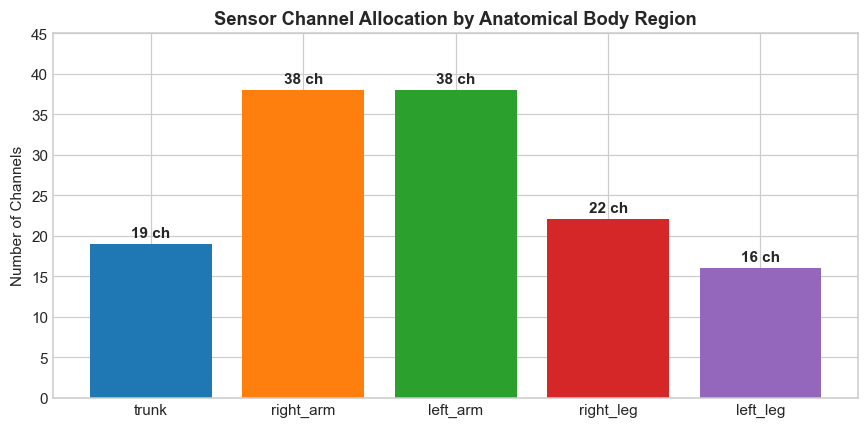

In [6]:
from src.features.body_regions import BODY_REGIONS, ANATOMICAL_SENSOR_COLUMNS

region_counts = {region: len(cols) for region, cols in ANATOMICAL_SENSOR_COLUMNS.items()}

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(BODY_REGIONS, [region_counts[r] for r in BODY_REGIONS], color=["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"])
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 0.5, f"{int(yval)} ch", ha="center", va="bottom", fontweight="bold")

ax.set_title("Sensor Channel Allocation by Anatomical Body Region", fontweight="bold")
ax.set_ylabel("Number of Channels")
ax.set_ylim(0, 45)
plt.tight_layout()
plt.show()


## 6. Leak-Free Preprocessing Pipeline

### Strict Research Methodology:
1. **No Data Leakage**: Standard normalization statistics (channel mean $\mu$ and standard deviation $\sigma$) are estimated strictly on training subjects ($S1, S2, S3$). Validation ($S2$) and test ($S3$) recordings are transformed using the fitted training statistics.
2. **Boundary Integrity**: Sliding windows are constructed strictly within continuous recording runs without concatenating sessions across run boundaries.
3. **Sliding Windows**:
   - Window size: $30$ samples ($1.0$ second duration at $30$ Hz).
   - Overlap stride: $15$ samples ($50\%$ overlap, $0.5$ second step).
   - Window Labeling: Mode (most frequent label) in the window segment.


In [7]:
# Check existing processed subset or trigger preprocessing
processed_file = REPO_ROOT / "data" / "processed" / "opportunity_locomotion_subset.npz"

if not processed_file.exists():
    print("[INFO] Processing dataset from raw recordings...")
    summary = api.preprocess_data(
        track="Locomotion",
        output_filename="opportunity_locomotion_subset.npz",
        window_size=30,
        stride=15
    )
    print("Preprocessing Summary:", summary)
else:
    print(f"[OK] Preprocessed dataset archive ready at: {processed_file.name}")


[OK] Preprocessed dataset archive ready at: opportunity_locomotion_subset.npz


## 7. Preprocessed Tensor Verification & Class Balance EDA

Let's load the generated window tensors and verify their shapes, split ratios, and class distributions.


In [8]:
subset = api.load_preprocessed_subset("opportunity_locomotion_subset.npz")

X_train, y_train = subset["X_train"], subset["y_train"]
X_val, y_val = subset["X_val"], subset["y_val"]
X_test, y_test = subset["X_test"], subset["y_test"]
class_names = subset["class_names"]

print("Generated Tensor Shapes:")
print(f"  Training Set   : X = {X_train.shape}  |  y = {y_train.shape}")
print(f"  Validation Set : X = {X_val.shape}    |  y = {y_val.shape}")
print(f"  Testing Set    : X = {X_test.shape}   |  y = {y_test.shape}")
print(f"  Class Names    : {class_names}")

total_windows = len(y_train) + len(y_val) + len(y_test)
print(f"\nTotal Dataset Windows : {total_windows:,}")
print(f"Split Percentages     : Train {len(y_train)/total_windows*100:.1f}% | Val {len(y_val)/total_windows*100:.1f}% | Test {len(y_test)/total_windows*100:.1f}%")


Generated Tensor Shapes:
  Training Set   : X = (9966, 133, 30)  |  y = (9966,)
  Validation Set : X = (4302, 133, 30)    |  y = (4302,)
  Testing Set    : X = (3609, 133, 30)   |  y = (3609,)
  Class Names    : ['Null', 'Stand', 'Walk', 'Sit', 'Lie']

Total Dataset Windows : 17,877
Split Percentages     : Train 55.7% | Val 24.1% | Test 20.2%


## 8. Locomotion Class Distribution & Class Imbalance Analysis

Real-world activity datasets exhibit significant class imbalance, with static postures (Stand, Walk, Sit) dominating over transitionary or rare states.


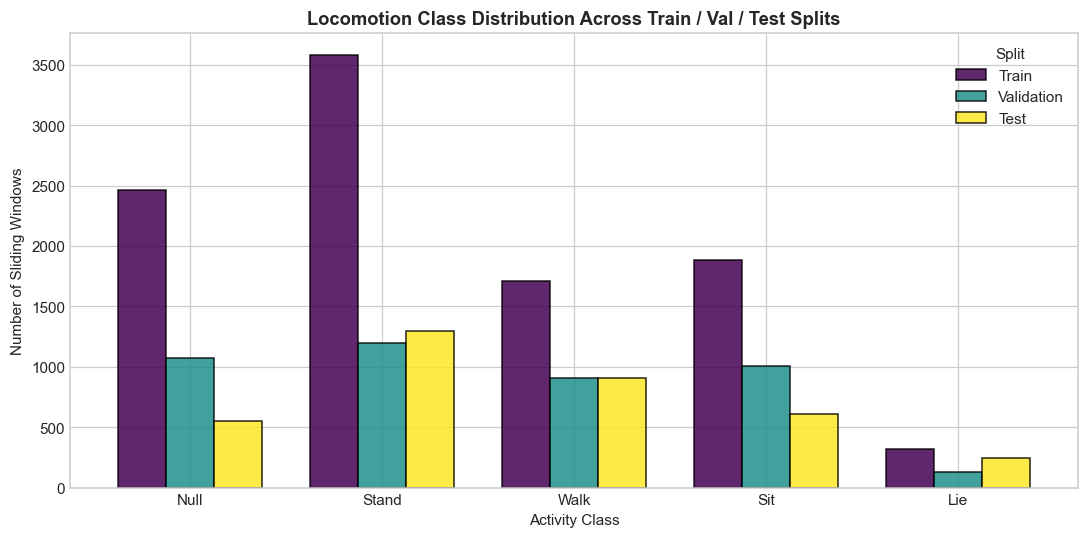

,Train,Validation,Test,Total,Proportion (%)
Null,2461,1070,554,4085,22.850590
Stand,3583,1194,1292,6069,33.948649
Walk,1714,908,907,3529,19.740449
Sit,1887,1004,611,3502,19.589417
Lie,321,126,245,692,3.870896


In [9]:
# Compute class counts per split
splits_data = {
    "Train": pd.Series(y_train).value_counts().sort_index(),
    "Validation": pd.Series(y_val).value_counts().sort_index(),
    "Test": pd.Series(y_test).value_counts().sort_index()
}
df_dist = pd.DataFrame(splits_data).fillna(0)
df_dist.index = [class_names[i] for i in df_dist.index]

fig, ax = plt.subplots(figsize=(10, 5))
df_dist.plot(kind="bar", ax=ax, colormap="viridis", width=0.75, edgecolor="black", alpha=0.85)
ax.set_title("Locomotion Class Distribution Across Train / Val / Test Splits", fontweight="bold")
ax.set_xlabel("Activity Class")
ax.set_ylabel("Number of Sliding Windows")
ax.legend(title="Split")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Display percentage distribution table
df_dist["Total"] = df_dist.sum(axis=1)
df_dist["Proportion (%)"] = (df_dist["Total"] / df_dist["Total"].sum()) * 100
display(df_dist)


## 9. Visualizing Normalized Window Waveforms Across Classes

Here, we plot representative $1.0$-second ($30$ samples) normalized window instances for each activity class to observe temporal patterns in standardized sensor space.


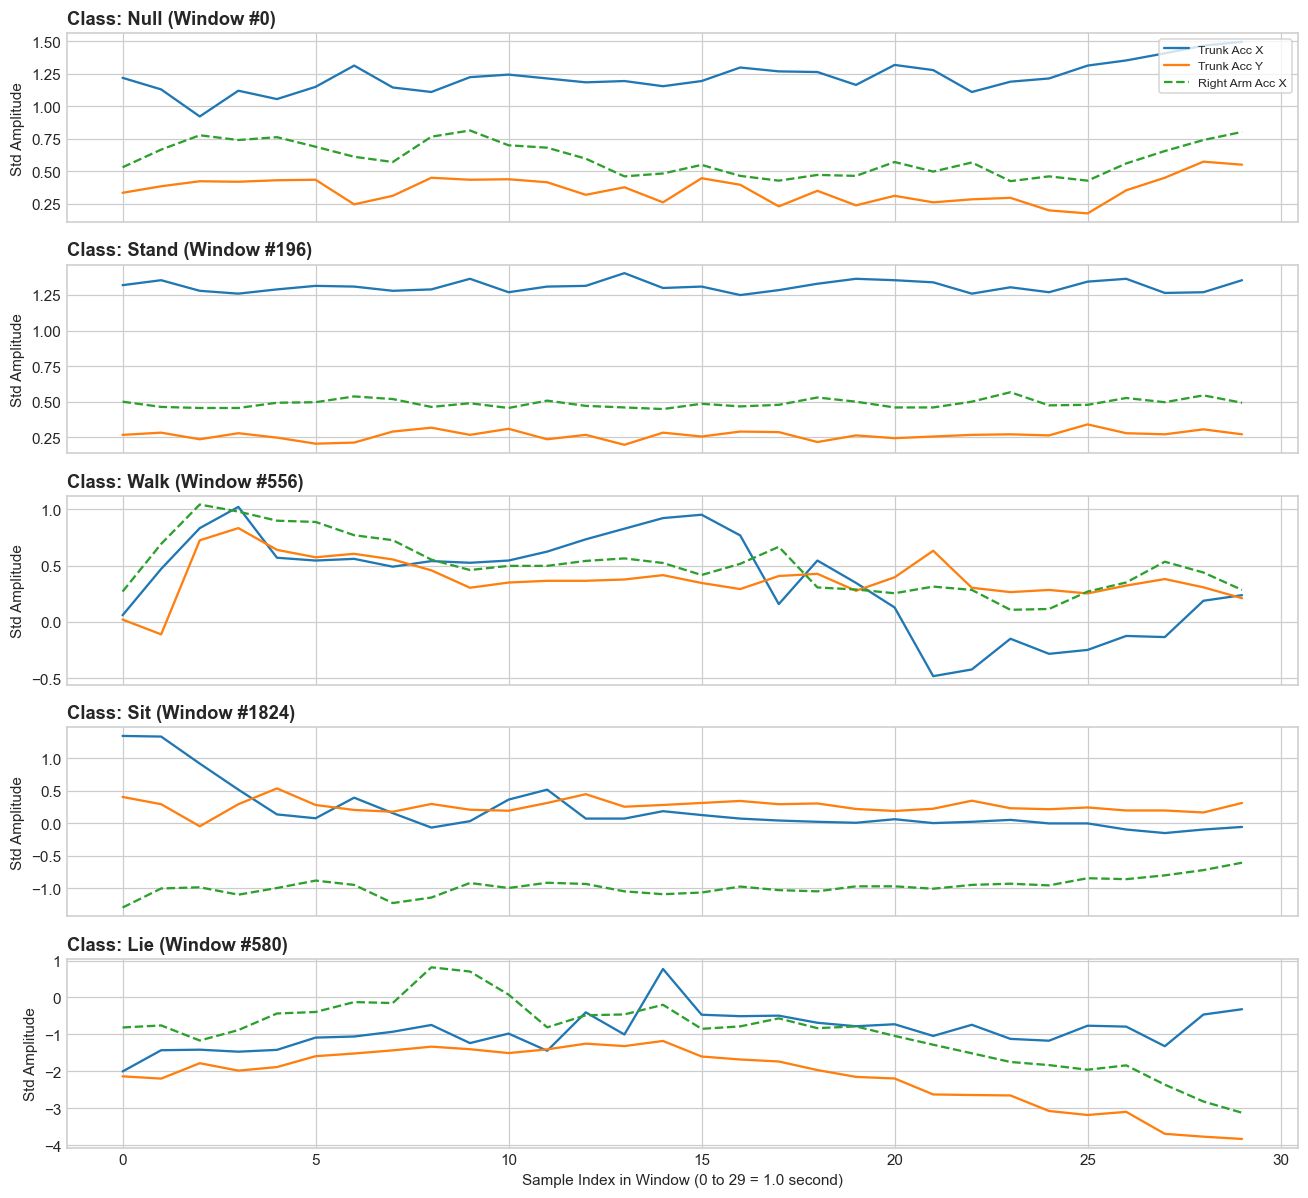

In [10]:
fig, axes = plt.subplots(len(class_names), 1, figsize=(12, 11), sharex=True)

# Select first representative window of each class from training set
for c_idx, c_name in enumerate(class_names):
    matches = np.where(y_train == c_idx)[0]
    if len(matches) > 0:
        sample_w = X_train[matches[0]]  # Shape: (133, 30)
        
        # Plot Trunk Acc (channels 3, 4, 5) and Right Arm Acc (channels 25, 26, 27)
        axes[c_idx].plot(sample_w[3], label="Trunk Acc X", color="#1f77b4")
        axes[c_idx].plot(sample_w[4], label="Trunk Acc Y", color="#ff7f0e")
        axes[c_idx].plot(sample_w[25], label="Right Arm Acc X", color="#2ca02c", linestyle="--")
        axes[c_idx].set_title(f"Class: {c_name} (Window #{matches[0]})", fontweight="bold", loc="left")
        axes[c_idx].set_ylabel("Std Amplitude")
        if c_idx == 0:
            axes[c_idx].legend(loc="upper right", frameon=True, fontsize=8)

axes[-1].set_xlabel("Sample Index in Window (0 to 29 = 1.0 second)")
plt.tight_layout()
plt.show()


## 10. Statistical Feature Distributions & Channel Correlations

Before feeding window tensors to deep learning or baseline models, we extract window statistics (Mean, Standard Deviation, Peak-to-Peak amplitude) across representative body channels to verify signal separation.


C:\Users\DELL\AppData\Local\Temp\ipykernel_17928\1778953405.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_features, x="Activity", y="Trunk_Std", ax=axes[0], palette="Set2")


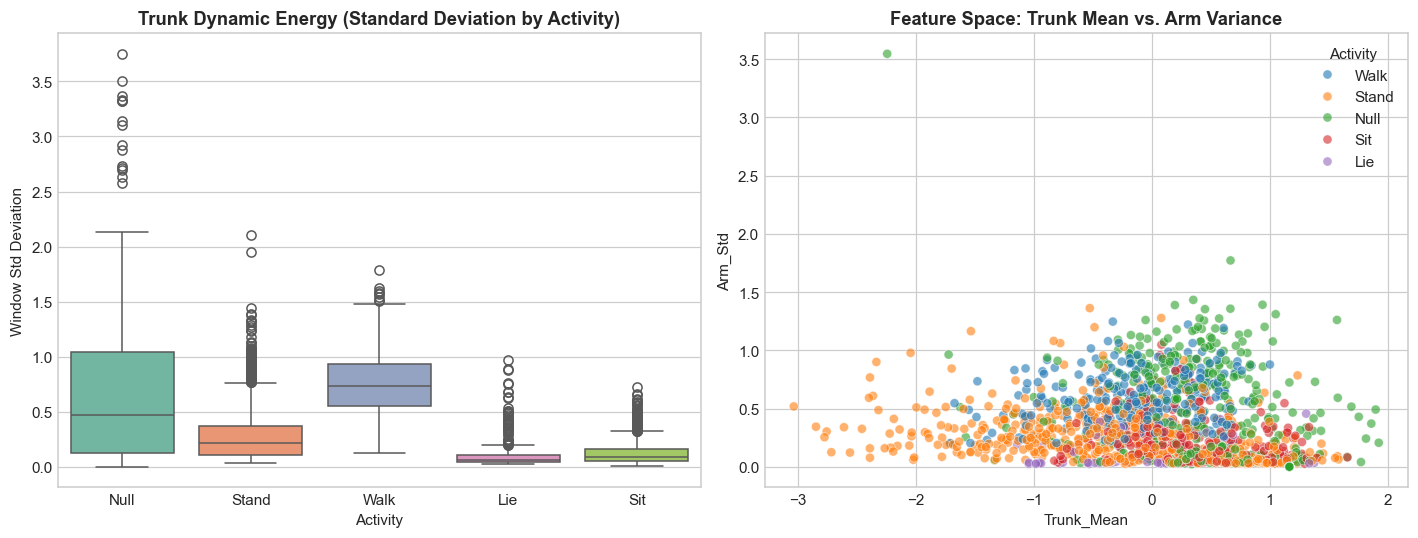

[EDA & Preprocessing Completed Successfully]


In [11]:
# Extract mean and std per window for Trunk Acc (channel 3) and Right Arm Acc (channel 25)
trunk_mean = np.mean(X_train[:, 3, :], axis=1)
trunk_std = np.std(X_train[:, 3, :], axis=1)
arm_std = np.std(X_train[:, 25, :], axis=1)

df_features = pd.DataFrame({
    "Trunk_Mean": trunk_mean,
    "Trunk_Std": trunk_std,
    "Arm_Std": arm_std,
    "Activity": [class_names[y] for y in y_train]
})

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Dynamic energy (Standard Deviation) comparison
sns.boxplot(data=df_features, x="Activity", y="Trunk_Std", ax=axes[0], palette="Set2")
axes[0].set_title("Trunk Dynamic Energy (Standard Deviation by Activity)", fontweight="bold")
axes[0].set_ylabel("Window Std Deviation")

sns.scatterplot(data=df_features.sample(n=min(1500, len(df_features)), random_state=42), 
                x="Trunk_Mean", y="Arm_Std", hue="Activity", alpha=0.6, ax=axes[1], palette="tab10")
axes[1].set_title("Feature Space: Trunk Mean vs. Arm Variance", fontweight="bold")

plt.tight_layout()
plt.show()

print("[EDA & Preprocessing Completed Successfully]")
